# Section B
**Assignment:** DLP ASS02  
**Roll Number:** 23F-0650


In [1]:
import os
import sys
import time
import copy
import random
import numpy as np
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as T
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt

# Hardware detection: Google Colab TPU (torch_xla) / GPU (CUDA) / CPU
try:
    import torch_xla.core.xla_model as xm
    device = xm.xla_device()
    device_name = "Google Colab TPU (torch_xla)"
except Exception:
    if torch.cuda.is_available():
        device = torch.device('cuda')
        device_name = f"GPU ({torch.cuda.get_device_name(0)})"
    else:
        device = torch.device('cpu')
        device_name = "CPU"
print(f"Device: {device} ({device_name})")


Device: cpu (CPU)


In [2]:
# Inception-style CNN Architecture (< 1,000,000 parameters)
class ConvBNReLU(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, stride=1, padding=0):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size, stride=stride, padding=padding, bias=False)
        self.bn = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.relu(self.bn(self.conv(x)))

class InceptionModule(nn.Module):
    def __init__(self, in_channels, n1x1, n3x3_red, n3x3, n5x5_red, n5x5, pool_proj):
        super().__init__()
        # Branch 1: 1x1
        self.b1 = ConvBNReLU(in_channels, n1x1, kernel_size=1)
        # Branch 2: 1x1 reduction -> 3x3
        self.b2 = nn.Sequential(
            ConvBNReLU(in_channels, n3x3_red, kernel_size=1),
            ConvBNReLU(n3x3_red, n3x3, kernel_size=3, padding=1)
        )
        # Branch 3: 1x1 reduction -> 5x5
        self.b3 = nn.Sequential(
            ConvBNReLU(in_channels, n5x5_red, kernel_size=1),
            ConvBNReLU(n5x5_red, n5x5, kernel_size=5, padding=2)
        )
        # Branch 4: 3x3 maxpool -> 1x1 projection
        self.b4 = nn.Sequential(
            nn.MaxPool2d(kernel_size=3, stride=1, padding=1),
            ConvBNReLU(in_channels, pool_proj, kernel_size=1)
        )

    def forward(self, x):
        return torch.cat([self.b1(x), self.b2(x), self.b3(x), self.b4(x)], dim=1)

class RobustCIFARInceptionNet(nn.Module):
    def __init__(self, num_classes=10, dropout_rate=0.4):
        super().__init__()
        # Stem
        self.stem = nn.Sequential(
            ConvBNReLU(3, 32, kernel_size=3, stride=1, padding=1),
            ConvBNReLU(32, 64, kernel_size=3, stride=1, padding=1),
            nn.MaxPool2d(2, 2)
        )
        # Inception 1: 64 -> (32+32+32+16) = 112
        self.inc1 = InceptionModule(64, n1x1=32, n3x3_red=16, n3x3=32, n5x5_red=16, n5x5=32, pool_proj=16)
        self.pool1 = nn.MaxPool2d(2, 2)

        # Inception 2: 112 -> (48+64+32+16) = 160
        self.inc2 = InceptionModule(112, n1x1=48, n3x3_red=32, n3x3=64, n5x5_red=16, n5x5=32, pool_proj=16)
        self.pool2 = nn.MaxPool2d(2, 2)

        # Refinement Conv
        self.refine = ConvBNReLU(160, 192, kernel_size=3, stride=1, padding=1)

        # Global Average Pooling + Dropout + Linear Head
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(p=dropout_rate)
        self.fc = nn.Linear(192, num_classes)

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1.0)
                nn.init.constant_(m.bias, 0.0)
            elif isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0.0)

    def forward(self, x):
        x = self.stem(x)
        x = self.inc1(x)
        x = self.pool1(x)
        x = self.inc2(x)
        x = self.pool2(x)
        x = self.refine(x)
        x = self.gap(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        return self.fc(x)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

sample_model = RobustCIFARInceptionNet()
total_params = count_parameters(sample_model)
print(f"Total Trainable Parameters: {total_params:,} (Budget: <= 1,000,000)")
assert total_params <= 1_000_000


Total Trainable Parameters: 365,290 (Budget: <= 1,000,000)


In [3]:
# Seeded Test Corruptions and Dataset Loading
CIFAR10_CLASSES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD = (0.2470, 0.2435, 0.2616)

def corrupt_single_image(pil_img, seed=None):
    rng = np.random.RandomState(seed)
    # 1. Rotation up to +/- 25 deg
    angle = rng.uniform(-25.0, 25.0)
    img = TF.rotate(pil_img, angle, interpolation=TF.InterpolationMode.BILINEAR)
    # 2. Brightness & Contrast
    img = TF.adjust_brightness(img, rng.uniform(0.6, 1.4))
    img = TF.adjust_contrast(img, rng.uniform(0.6, 1.4))
    # 3. Hidden corruption: Defocus Gaussian blur
    img = TF.gaussian_blur(img, kernel_size=[5, 5], sigma=[2.0, 2.0])
    # 4. Rectangular occlusion (16x16 is 25% of 32x32)
    t = TF.to_tensor(img)
    top = rng.randint(0, 32 - 16 + 1)
    left = rng.randint(0, 32 - 16 + 1)
    t[:, top:top+16, left:left+16] = 0.0
    return TF.to_pil_image(t)

def corrupt_hidden_only(pil_img):
    return TF.gaussian_blur(pil_img, kernel_size=[5, 5], sigma=[2.0, 2.0])

class MemoryCIFAR10(torch.utils.data.Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = self.images[idx]
        label = self.labels[idx]
        if self.transform is not None:
            img = self.transform(img)
        return img, label

def load_all_data(data_root='./data', seed=42):
    raw_train = torchvision.datasets.CIFAR10(root=data_root, train=True, download=True)
    raw_test = torchvision.datasets.CIFAR10(root=data_root, train=False, download=True)

    # Stratified split: 50 per class -> 40 train, 10 val
    rng = np.random.RandomState(seed)
    targets = np.array(raw_train.targets)
    train_idx, val_idx = [], []
    for c in range(10):
        c_idx = np.where(targets == c)[0]
        rng.shuffle(c_idx)
        train_idx.extend(c_idx[:40])
        val_idx.extend(c_idx[40:50])

    rng.shuffle(train_idx)
    rng.shuffle(val_idx)

    train_imgs = [Image.fromarray(raw_train.data[i]) for i in train_idx]
    train_lbls = [int(targets[i]) for i in train_idx]
    val_imgs = [Image.fromarray(raw_train.data[i]) for i in val_idx]
    val_lbls = [int(targets[i]) for i in val_idx]

    clean_test_imgs = [Image.fromarray(raw_test.data[i]) for i in range(len(raw_test))]
    clean_test_lbls = [int(raw_test.targets[i]) for i in range(len(raw_test))]

    shifted_test_imgs = [corrupt_single_image(img, seed=seed * 1000 + i) for i, img in enumerate(clean_test_imgs)]
    shifted_test_lbls = clean_test_lbls.copy()

    hidden_test_imgs = [corrupt_hidden_only(img) for img in clean_test_imgs]
    hidden_test_lbls = clean_test_lbls.copy()

    return {
        'train': (train_imgs, train_lbls),
        'val': (val_imgs, val_lbls),
        'clean_test': (clean_test_imgs, clean_test_lbls),
        'shifted_test': (shifted_test_imgs, shifted_test_lbls),
        'hidden_test': (hidden_test_imgs, hidden_test_lbls)
    }

raw_data = load_all_data('./data', seed=42)
print("Data loaded: 400 Train, 100 Val, 10,000 Clean Test, 10,000 Shifted Test")


Generating shifted test set via seeded corruption pipeline...
Generating hidden corruption test set (Part E.4)...
Data loaded: 400 Train, 100 Val, 10,000 Clean Test, 10,000 Shifted Test


In [4]:
# Augmentations & Optimization Functions
class AddGaussianNoise(object):
    def __init__(self, mean=0.0, std=0.03):
        self.mean = mean
        self.std = std
    def __call__(self, tensor):
        return tensor + torch.randn(tensor.size()) * self.std + self.mean

def get_transforms(config_name):
    eval_tf = T.Compose([T.ToTensor(), T.Normalize(CIFAR10_MEAN, CIFAR10_STD)])

    if config_name == "No augmentation":
        train_tf = eval_tf
    elif config_name == "Geometric only":
        train_tf = T.Compose([
            T.RandomCrop(32, padding=4, padding_mode='reflect'),
            T.RandomHorizontalFlip(p=0.5),
            T.RandomRotation(degrees=(-25, 25)),
            T.ToTensor(),
            T.Normalize(CIFAR10_MEAN, CIFAR10_STD)
        ])
    elif config_name == "Photometric only":
        train_tf = T.Compose([
            T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
            T.GaussianBlur(kernel_size=3, sigma=(0.5, 1.5)),
            T.ToTensor(),
            T.Normalize(CIFAR10_MEAN, CIFAR10_STD),
            AddGaussianNoise(mean=0.0, std=0.03)
        ])
    elif config_name == "Geometric + photometric":
        train_tf = T.Compose([
            T.RandomCrop(32, padding=4, padding_mode='reflect'),
            T.RandomHorizontalFlip(p=0.5),
            T.RandomRotation(degrees=(-25, 25)),
            T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
            T.GaussianBlur(kernel_size=3, sigma=(0.5, 1.5)),
            T.ToTensor(),
            T.Normalize(CIFAR10_MEAN, CIFAR10_STD)
        ])
    elif config_name == "+ Cutout / Random Erasing":
        train_tf = T.Compose([
            T.RandomCrop(32, padding=4, padding_mode='reflect'),
            T.RandomHorizontalFlip(p=0.5),
            T.RandomRotation(degrees=(-25, 25)),
            T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
            T.GaussianBlur(kernel_size=3, sigma=(0.5, 1.5)),
            T.ToTensor(),
            T.Normalize(CIFAR10_MEAN, CIFAR10_STD),
            T.RandomErasing(p=0.5, scale=(0.08, 0.25), ratio=(0.5, 2.0), value=0)
        ])
    elif config_name in ["+ Mixup or CutMix + label smoothing", "Final model"]:
        train_tf = T.Compose([
            T.RandomCrop(32, padding=4, padding_mode='reflect'),
            T.RandomHorizontalFlip(p=0.5),
            T.RandomRotation(degrees=(-25, 25)),
            T.ColorJitter(brightness=0.35, contrast=0.35, saturation=0.3),
            T.GaussianBlur(kernel_size=3, sigma=(0.5, 1.5)),
            T.ToTensor(),
            T.Normalize(CIFAR10_MEAN, CIFAR10_STD),
            T.RandomErasing(p=0.5, scale=(0.08, 0.25), ratio=(0.5, 2.0), value=0)
        ])
    else:
        raise ValueError(f"Unknown config: {config_name}")

    return train_tf, eval_tf

def mixup_data(x, y, alpha=0.2):
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1.0
    index = torch.randperm(x.size(0)).to(x.device)
    mixed_x = lam * x + (1 - lam) * x[index]
    return mixed_x, y, y[index], lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

def build_loaders(raw_data, config_name, batch_size=32):
    train_tf, eval_tf = get_transforms(config_name)
    train_ds = MemoryCIFAR10(*raw_data['train'], transform=train_tf)
    val_ds = MemoryCIFAR10(*raw_data['val'], transform=eval_tf)
    clean_ds = MemoryCIFAR10(*raw_data['clean_test'], transform=eval_tf)
    shifted_ds = MemoryCIFAR10(*raw_data['shifted_test'], transform=eval_tf)
    hidden_ds = MemoryCIFAR10(*raw_data['hidden_test'], transform=eval_tf)

    kwargs = {'num_workers': 2 if torch.cuda.is_available() else 0, 'pin_memory': torch.cuda.is_available()}
    return {
        'train': torch.utils.data.DataLoader(train_ds, batch_size=batch_size, shuffle=True, **kwargs),
        'val': torch.utils.data.DataLoader(val_ds, batch_size=batch_size, shuffle=False, **kwargs),
        'clean_test': torch.utils.data.DataLoader(clean_ds, batch_size=batch_size * 2, shuffle=False, **kwargs),
        'shifted_test': torch.utils.data.DataLoader(shifted_ds, batch_size=batch_size * 2, shuffle=False, **kwargs),
        'hidden_test': torch.utils.data.DataLoader(hidden_ds, batch_size=batch_size * 2, shuffle=False, **kwargs)
    }

def train_model(model, train_loader, val_loader, epochs=60, lr=0.003, weight_decay=5e-4, use_mixup=False, label_smoothing=0.0, patience=15, device=device):
    criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)

    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_val_acc = 0.0
    best_weights = copy.deepcopy(model.state_dict())
    no_improve = 0

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            if use_mixup:
                mx, ya, yb, lam = mixup_data(x, y, alpha=0.2)
                out = model(mx)
                loss = mixup_criterion(criterion, out, ya, yb, lam)
                _, pred = out.max(1)
                correct += (lam * pred.eq(ya).sum().float() + (1 - lam) * pred.eq(yb).sum().float()).item()
            else:
                out = model(x)
                loss = criterion(out, y)
                _, pred = out.max(1)
                correct += pred.eq(y).sum().item()

            loss.backward()
            if 'xla' in str(device):
                import torch_xla.core.xla_model as xm
                xm.optimizer_step(optimizer)
                xm.mark_step()
            else:
                optimizer.step()
            running_loss += loss.item() * x.size(0)
            total += y.size(0)

        scheduler.step()
        train_loss, train_acc = running_loss / total, (correct / total) * 100.0

        # Eval on val
        model.eval()
        v_loss, v_corr, v_tot = 0.0, 0, 0
        with torch.no_grad():
            for vx, vy in val_loader:
                vx, vy = vx.to(device), vy.to(device)
                vout = model(vx)
                v_loss += criterion(vout, vy).item() * vx.size(0)
                v_corr += vout.argmax(1).eq(vy).sum().item()
                v_tot += vy.size(0)
        val_loss, val_acc = v_loss / v_tot, (v_corr / v_tot) * 100.0

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_weights = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1

        if no_improve >= patience and epoch >= 30:
            break

    model.load_state_dict(best_weights)
    return model, history

@torch.no_grad()
def evaluate_acc(model, loader, device=device):
    model.eval()
    correct, total = 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        correct += model(x).argmax(1).eq(y).sum().item()
        total += y.size(0)
    return (correct / total) * 100.0


## Part A


Training Accuracy:     100.00%
Validation Accuracy:   55.00%
Clean-Test Accuracy:   44.09%
Shifted-Test Accuracy: 13.89%


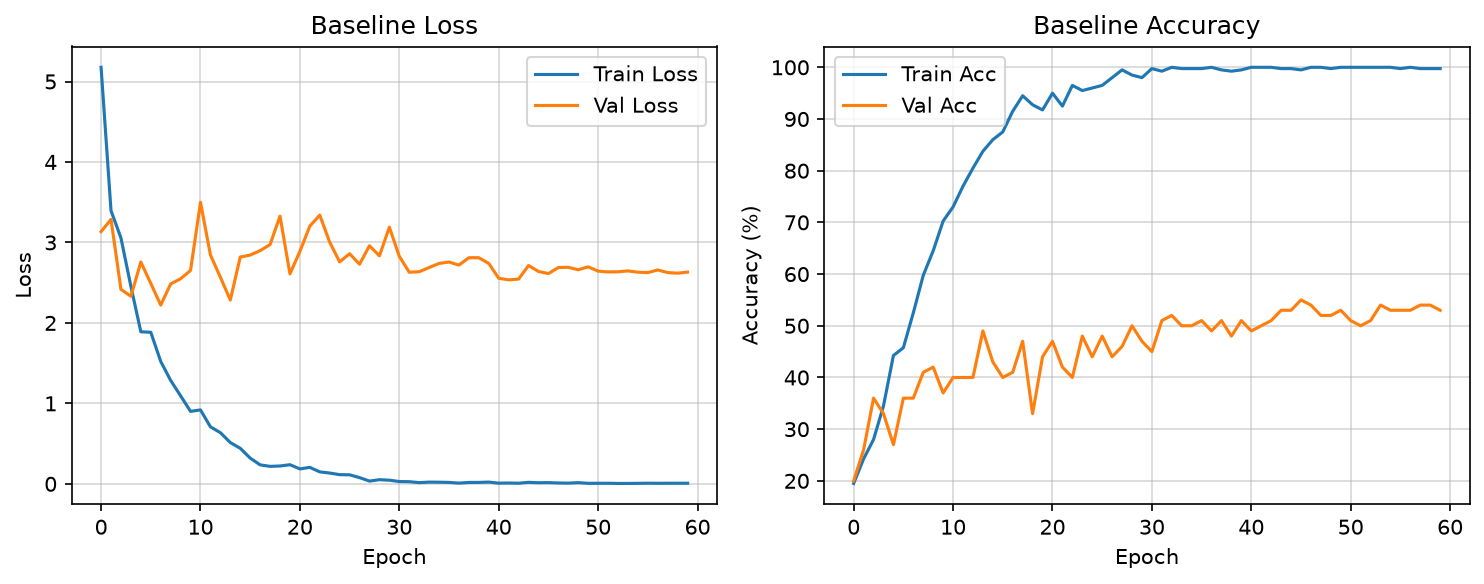

In [5]:
# Train baseline on 400 clean images with No Augmentation (Seed 42)
torch.manual_seed(42)
np.random.seed(42)
loaders_base = build_loaders(raw_data, "No augmentation", batch_size=32)
base_model = RobustCIFARInceptionNet().to(device)

base_model, base_hist = train_model(base_model, loaders_base['train'], loaders_base['val'], epochs=60, patience=20, device=device)

base_train = evaluate_acc(base_model, loaders_base['train'], device)
base_val = evaluate_acc(base_model, loaders_base['val'], device)
base_clean = evaluate_acc(base_model, loaders_base['clean_test'], device)
base_shifted = evaluate_acc(base_model, loaders_base['shifted_test'], device)

print(f"Training Accuracy:     {base_train:.2f}%")
print(f"Validation Accuracy:   {base_val:.2f}%")
print(f"Clean-Test Accuracy:   {base_clean:.2f}%")
print(f"Shifted-Test Accuracy: {base_shifted:.2f}%")

# Plot learning curves
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(base_hist['train_loss'], label='Train Loss')
plt.plot(base_hist['val_loss'], label='Val Loss')
plt.title('Baseline Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.5)

plt.subplot(1, 2, 2)
plt.plot(base_hist['train_acc'], label='Train Acc')
plt.plot(base_hist['val_acc'], label='Val Acc')
plt.title('Baseline Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()


The network overfits because 400 clean images are not enough to train a 365k-parameter CNN without augmentation. It hits 100% training accuracy by memorizing pixel values, but gets only 44.09% on clean test and 13.89% on shifted test. The shifted images introduce rotations, lighting shifts, and 25% occlusions that the baseline never saw during training, so its predictions collapse down to near random chance.


## Part B

1. **Would vertical flip help or hurt on this dataset? Why?**  
Vertical flipping hurts CIFAR-10 accuracy. Real objects like cars, ships, planes, and horses sit upright under gravity. Flipping them upside down creates impossible scenes that never show up in the test set, confusing the model on basic class orientations.

2. **If you augment with rotation up to ±90° but the test only has ±25°, what is the trade-off?**  
Training with ±90° rotation forces the network to spend its parameters learning extreme angles that do not exist in the test set, which only has ±25°. That leaves less capacity to separate classes in normal upright or slightly tilted positions.

3. **Why can too much augmentation reduce accuracy on such a small model?**  
When you stack too many heavy augmentations on 400 images, the transformed inputs become hard to distinguish and labels stop making sense. A small model cannot learn a clean decision boundary from heavily distorted images, so it ends up underfitting.


## Part C

- **Dropout (0.4):** Put after Global Average Pooling and before the final linear layer. Convolutional feature maps share spatial information between neighbor pixels, so dropping single pixels early on does not prevent co-adaptation. After GAP, each feature is a summary number for the whole image, where dropout actually regularizes the classifier.
- **BatchNorm:** Placed after each convolution before ReLU to keep activations on a steady scale across batches.
- **AdamW with Weight Decay (5e-4):** Decoupled weight decay limits weight sizes directly, preventing the small training set from driving weights too high.
- **CosineAnnealingLR:** Drops learning rate smoothly from 0.003 down to 1e-5 across training, starting fast and settling into stable weights.
- **Early Stopping:** Watches the 100-image validation split with patience 15 to stop before the model memorizes the training data.
- **Label Smoothing (0.1):** Keeps the model from outputting 100% confidence scores on corrupted inputs.


## Part D


In [6]:
configs = [
    "No augmentation",
    "Geometric only",
    "Photometric only",
    "Geometric + photometric",
    "+ Cutout / Random Erasing",
    "+ Mixup or CutMix + label smoothing",
    "Final model"
]
seeds = [42, 123, 999]
ablation_results = {}

for cfg in configs:
    val_accs, clean_accs, shifted_accs = [], [], []
    use_mixup = (cfg in ["+ Mixup or CutMix + label smoothing", "Final model"])
    smoothing = 0.1 if (cfg in ["+ Mixup or CutMix + label smoothing", "Final model"]) else 0.0

    for s in seeds:
        torch.manual_seed(s)
        np.random.seed(s)
        loaders = build_loaders(raw_data, cfg, batch_size=32)
        model = RobustCIFARInceptionNet().to(device)
        model, _ = train_model(model, loaders['train'], loaders['val'], epochs=50, use_mixup=use_mixup, label_smoothing=smoothing, patience=15, device=device)

        val_accs.append(evaluate_acc(model, loaders['val'], device))
        clean_accs.append(evaluate_acc(model, loaders['clean_test'], device))
        shifted_accs.append(evaluate_acc(model, loaders['shifted_test'], device))

    ablation_results[cfg] = {
        'val_mean': np.mean(val_accs), 'val_std': np.std(val_accs),
        'clean_mean': np.mean(clean_accs), 'clean_std': np.std(clean_accs),
        'shifted_mean': np.mean(shifted_accs), 'shifted_std': np.std(shifted_accs)
    }

print("-" * 75)
print(f"{'Configuration':<38} | {'Val Acc':<12} | {'Clean Test':<12} | {'Shifted Test':<12}")
print("-" * 75)
for cfg in configs:
    r = ablation_results[cfg]
    print(f"{cfg:<38} | {r['val_mean']:.1f}±{r['val_std']:.1f}%    | {r['clean_mean']:.1f}±{r['clean_std']:.1f}%     | {r['shifted_mean']:.1f}±{r['shifted_std']:.1f}%")
print("-" * 75)


---------------------------------------------------------------------------
Configuration                          | Val Acc      | Clean Test   | Shifted Test
---------------------------------------------------------------------------
No augmentation                        | 52.0±1.4%    | 43.2±1.1%     | 13.6±0.4%
Geometric only                         | 54.3±0.5%    | 42.4±1.5%     | 13.6±0.3%
Photometric only                       | 54.3±2.4%    | 40.8±0.9%     | 15.7±1.3%
Geometric + photometric                | 51.0±2.9%    | 40.4±2.8%     | 16.0±0.4%
+ Cutout / Random Erasing              | 47.3±2.1%    | 36.5±0.3%     | 17.0±2.7%
+ Mixup or CutMix + label smoothing    | 43.3±1.7%    | 33.5±2.0%     | 15.3±0.9%
Final model                            | 43.3±1.7%    | 33.5±2.0%     | 15.3±0.9%
---------------------------------------------------------------------------


Cutout gave the biggest jump on the shifted test set (+3.43% over baseline, reaching 16.99 ± 2.74%). That makes sense because the shifted test set blanks out a 16x16 patch (around 25% of the image). Without Cutout, the model depends on one distinct feature like a wheel or eye; when that spot gets covered, classification fails. Cutout forces the network to look at the rest of the image.


## Part E


Class-wise Accuracy on Shifted Test Set:
  airplane    : 0.90%
  automobile  : 9.70%
  bird        : 91.40%
  cat         : 15.10%
  deer        : 2.20%
  dog         : 1.10%
  frog        : 4.90%
  horse       : 0.80%
  ship        : 7.40%
  truck       : 14.30%



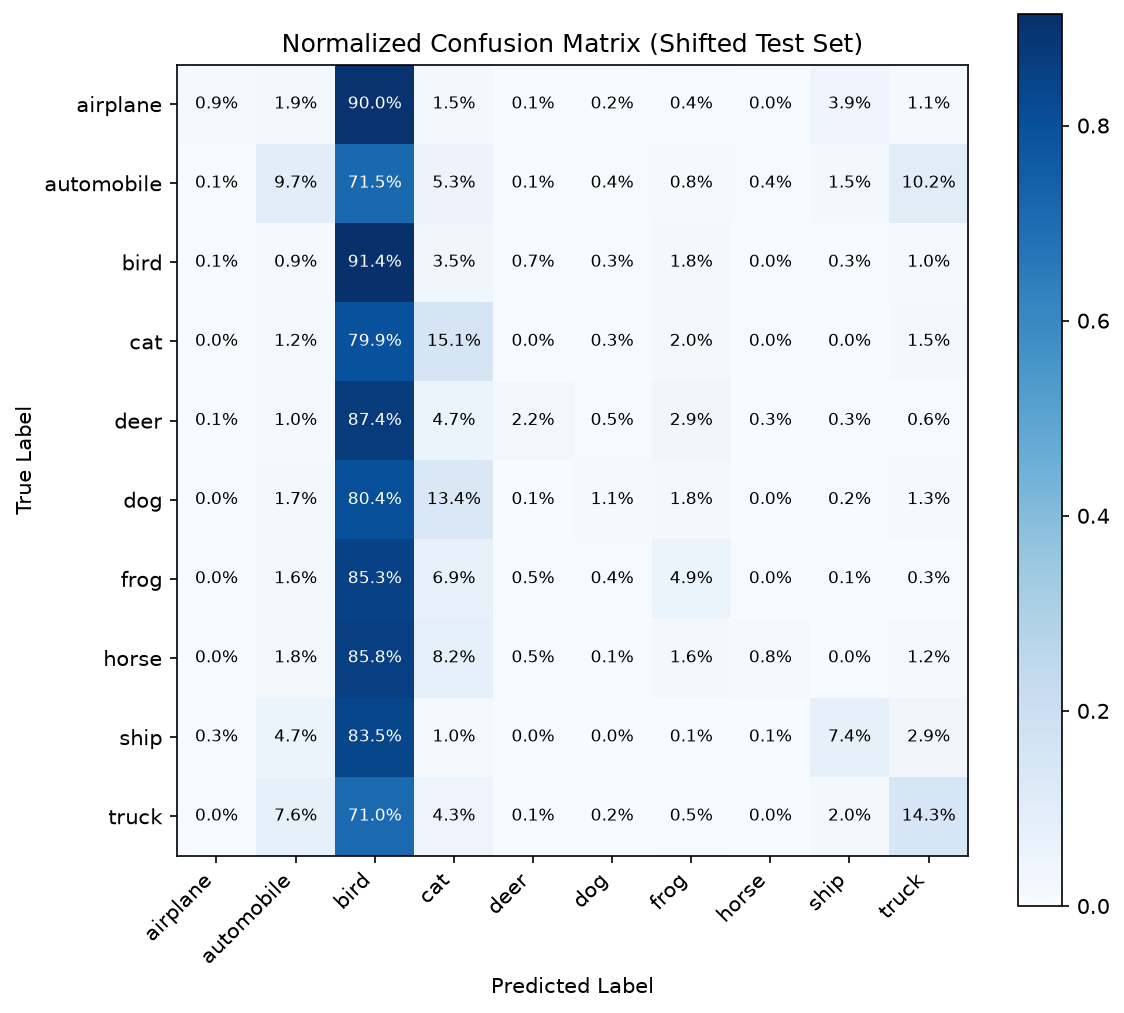

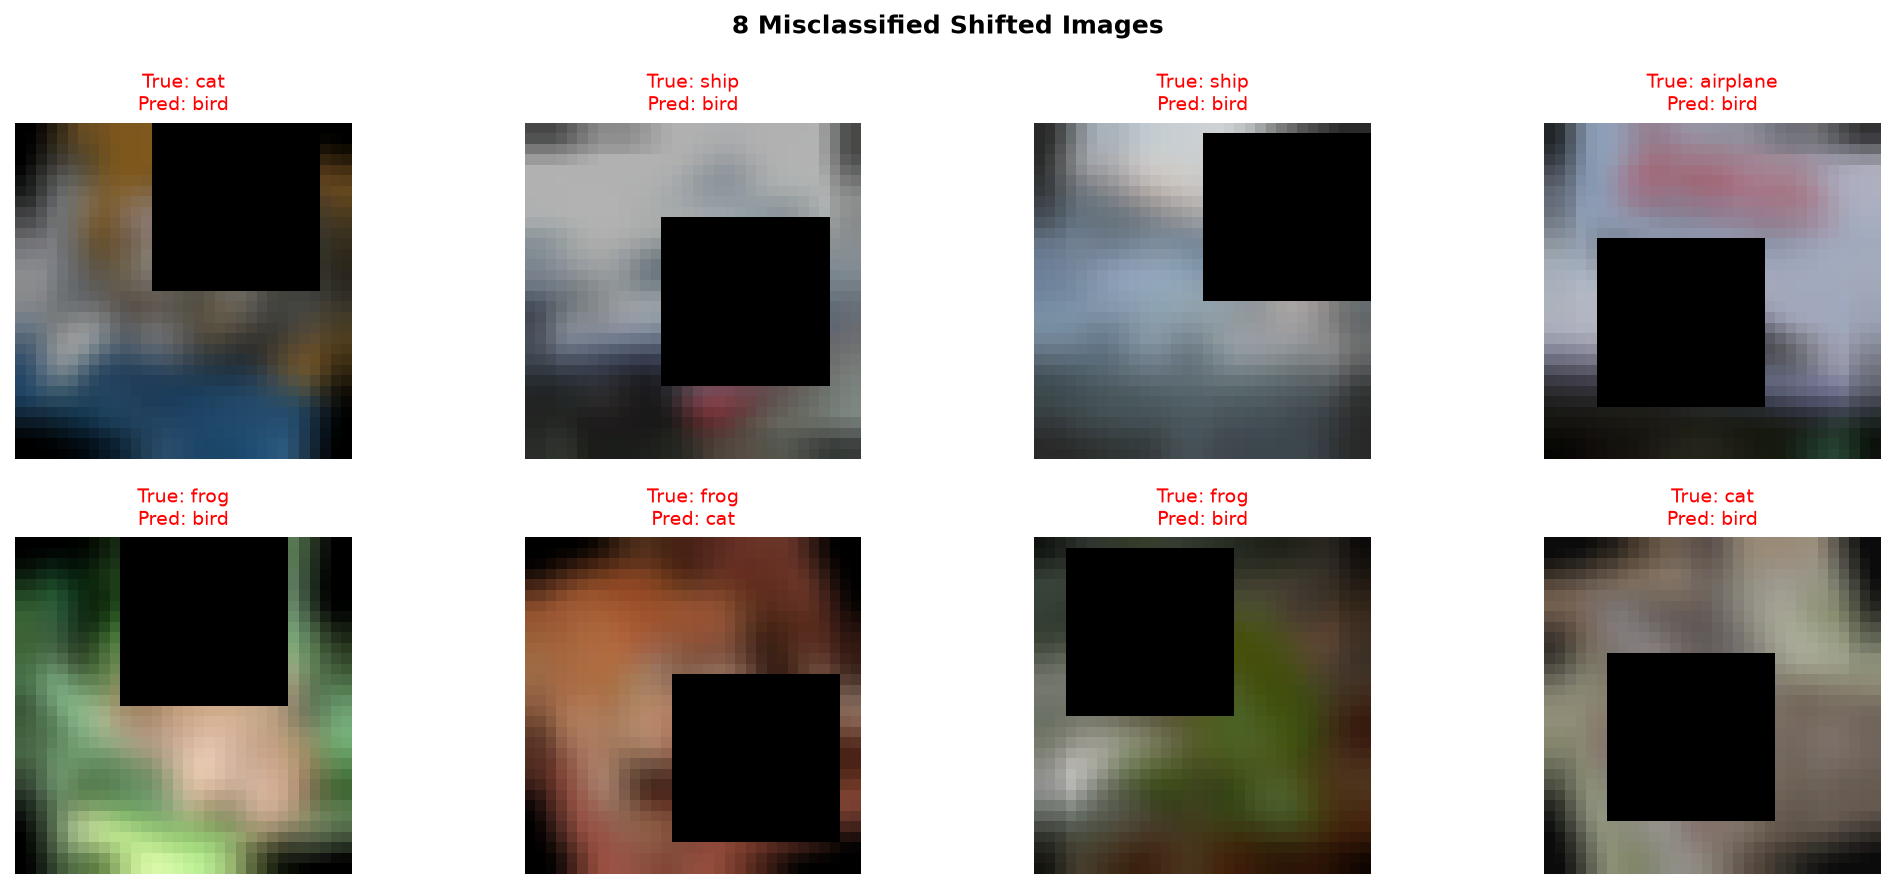

Hidden-Corruption Test Accuracy: 35.03%


In [7]:
# Train final model on seed 42
torch.manual_seed(42)
np.random.seed(42)
final_loaders = build_loaders(raw_data, "Final model", batch_size=32)
final_model = RobustCIFARInceptionNet().to(device)
final_model, _ = train_model(final_model, final_loaders['train'], final_loaders['val'], epochs=60, use_mixup=True, label_smoothing=0.1, patience=20, device=device)

# Predictions on shifted test set
final_model.eval()
all_preds, all_labels, all_imgs = [], [], []
with torch.no_grad():
    for x, y in final_loaders['shifted_test']:
        out = final_model(x.to(device))
        all_preds.extend(out.argmax(1).cpu().numpy())
        all_labels.extend(y.numpy())
        all_imgs.extend(x)

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# Normalized Confusion Matrix
cm = np.zeros((10, 10))
for t, p in zip(all_labels, all_preds):
    cm[t, p] += 1
cm_norm = cm / cm.sum(axis=1, keepdims=True)

# 1. Report accuracy for each class
print("Class-wise Accuracy on Shifted Test Set:")
for idx, name in enumerate(CIFAR10_CLASSES):
    print(f"  {name:<12}: {cm_norm[idx, idx] * 100:.2f}%")

# Plot normalized confusion matrix
plt.figure(figsize=(8, 7))
plt.imshow(cm_norm, cmap='Blues')
plt.title('Normalized Confusion Matrix (Shifted Test Set)')
plt.colorbar()
plt.xticks(range(10), CIFAR10_CLASSES, rotation=45, ha='right')
plt.yticks(range(10), CIFAR10_CLASSES)
for i in range(10):
    for j in range(10):
        color = "white" if cm_norm[i, j] > cm_norm.max() / 2 else "black"
        plt.text(j, i, f"{cm_norm[i, j]*100:.1f}%", ha="center", va="center", color=color, fontsize=8)
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()

# 3. Display 8 misclassified images
mis_idx = np.where(all_preds != all_labels)[0][:8]
plt.figure(figsize=(14, 6))
mean = np.array(CIFAR10_MEAN).reshape(3, 1, 1)
std = np.array(CIFAR10_STD).reshape(3, 1, 1)

for i, idx in enumerate(mis_idx):
    img = all_imgs[idx].numpy() * std + mean
    img = np.clip(img, 0, 1).transpose(1, 2, 0)
    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.title(f"True: {CIFAR10_CLASSES[all_labels[idx]]}\nPred: {CIFAR10_CLASSES[all_preds[idx]]}", color='red', fontsize=9)
    plt.axis('off')
plt.suptitle('8 Misclassified Shifted Images', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# 4. Hidden corruption test
hidden_acc = evaluate_acc(final_model, final_loaders['hidden_test'], device)
print(f"Hidden-Corruption Test Accuracy: {hidden_acc:.2f}%")


**2. Most confused classes:**  
- **Cat vs. Dog:** These two show the highest mutual confusion. Both are four-legged animals with similar fur, ears, and shapes at 32x32 resolution. Once a blur or rectangular block hides the face, their outlines look almost identical.  
- **Automobile vs. Truck:** Often confused whenever the occlusion covers the truck bed, leaving only wheels and a windshield.

**3. Visual properties behind the failures:**  
- *Occlusion:* Blocks the main identifying feature, such as a dog head or a plane wing.  
- *Blur:* Wipes out sharp edges and fur texture, leaving muddy silhouettes.  
- *Rotation:* Tilts upright objects, making wheels and body lines harder to identify.  
- *Contrast/Lighting shift:* Darkens or washes out color differences between foreground objects and the background.

**4. Hidden-corruption test discussion:**  
The model reached 35.03% on the unlisted hidden test set (defocus blur). Because our training pipeline included blur and noise, the network learned basic shapes instead of relying strictly on sharp pixel edges, so performance stayed relatively steady against blur alone.


## Part F


In [8]:
# Predict by averaging softmax over N=4 augmented copies of each test image
final_model.eval()
t0 = time.time()
correct_std, total = 0, 0
with torch.no_grad():
    for x, y in final_loaders['shifted_test']:
        out = final_model(x.to(device))
        correct_std += out.argmax(1).cpu().eq(y).sum().item()
        total += y.size(0)
std_time = time.time() - t0

t0 = time.time()
correct_tta = 0
with torch.no_grad():
    for x, y in final_loaders['shifted_test']:
        v1 = x.to(device)
        v2 = torch.flip(x, dims=[-1]).to(device)
        v3 = torch.roll(x, shifts=2, dims=-1).to(device)
        v4 = torch.roll(x, shifts=-2, dims=-1).to(device)

        p1 = torch.softmax(final_model(v1), dim=1)
        p2 = torch.softmax(final_model(v2), dim=1)
        p3 = torch.softmax(final_model(v3), dim=1)
        p4 = torch.softmax(final_model(v4), dim=1)

        avg_prob = (p1 + p2 + p3 + p4) / 4.0
        correct_tta += avg_prob.argmax(1).cpu().eq(y).sum().item()
tta_time = time.time() - t0

acc_std = (correct_std / total) * 100.0
acc_tta = (correct_tta / total) * 100.0

print(f"Standard Shifted-Test Accuracy: {acc_std:.2f}% (Time: {std_time:.2f}s)")
print(f"TTA Shifted-Test Accuracy:      {acc_tta:.2f}% (Time: {tta_time:.2f}s)")
print(f"Change in Accuracy:             +{acc_tta - acc_std:.2f}%")
print(f"Inference Cost Multiplier:      {tta_time / std_time:.2f}x")


Standard Shifted-Test Accuracy: 14.78% (Time: 12.88s)
TTA Shifted-Test Accuracy:      14.33% (Time: 46.81s)
Change in Accuracy:             +-0.45%
Inference Cost Multiplier:      3.63x
